<a href="https://colab.research.google.com/github/ahmed-id-machiche/deep_learning_tps/blob/main/TP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer dataset
data = load_breast_cancer()

# Extract the input features and target labels
X = data.data
y = data.target

# Display basic information about the dataset
print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", data.feature_names)
print("Target classes:", data.target_names)
print("Target values:", np.unique(y))


Dataset loaded successfully!
Number of samples: 569
Number of features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target classes: ['malignant' 'benign']
Target values: [0 1]


In [ ]:
# Import the functions needed for data preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
# Create the StandardScaler object
scaler = StandardScaler()

# Learn the scaling parameters from the training data
X_train = scaler.fit_transform(X_train)

# Apply the same scaling parameters to the test data
X_test = scaler.transform(X_test)

# Display the shapes of the resulting datasets
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

# Verify the standardization of the training features
print("Mean of the first training feature:", X_train[:, 0].mean())
print("Standard deviation of the first training feature:", X_train[:, 0].std())

Training features shape: (455, 30)
Testing features shape: (114, 30)
Training labels shape: (455,)
Testing labels shape: (114,)
Mean of the first training feature: -4.337433952909183e-15
Standard deviation of the first training feature: 1.0


In [ ]:
# Import Keras components
from tensorflow import keras
from tensorflow.keras import layers

# Create the neural network
model = keras.Sequential([
    # Input layer: 30 features
    layers.Input(shape=(30,)),

    # Hidden layer: 16 neurons with Sigmoid activation
    layers.Dense(16, activation="sigmoid"),

    # Output layer: 1 neuron with Sigmoid activation
    layers.Dense(1, activation="sigmoid")
])

# Configure the model for binary classification
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from sklearn.model_selection import train_test_split

# Split the training data into training and validation sets
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Display the dataset sizes
print("Training samples:", X_train_final.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 364
Validation samples: 91
Testing samples: 114


In [ ]:

from tensorflow import keras
from tensorflow.keras import layers

def build_model(activation_name):
    # Reset the random seed for reproducibility
    keras.utils.set_random_seed(42)

    # Create the neural network
    model = keras.Sequential()
    model.add(layers.Input(shape=(30,)))

    # Configure the hidden layer activation
    if activation_name == "leaky_relu":
        model.add(layers.Dense(16))
        model.add(layers.LeakyReLU(negative_slope=0.01))
    else:
        model.add(layers.Dense(16, activation=activation_name))

    # Output layer: sigmoid for binary classification
    model.add(layers.Dense(1, activation="sigmoid"))

    # Compile the model
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Build a ReLU model to verify the function
test_model = build_model("relu")
test_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Define the activation functions to compare
activations = ["sigmoid", "relu", "tanh", "leaky_relu"]

# Store the training history of each model
histories = {}

# Train one model for each activation function
for activation_name in activations:
    print(f"\nTraining model with {activation_name} activation")

    # Build a fresh model
    model = build_model(activation_name)

    # Train the model for 10 epochs
    history = model.fit(
        X_train_final,
        y_train_final,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=1
    )

    # Save the history for later comparison
    histories[activation_name] = history.history

print("\nAll experiments completed!")



Training model with sigmoid activation
Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8297 - loss: 0.6007 - val_accuracy: 0.8571 - val_loss: 0.5787
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8984 - loss: 0.5288 - val_accuracy: 0.9011 - val_loss: 0.5164
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9148 - loss: 0.4700 - val_accuracy: 0.9011 - val_loss: 0.4659
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9148 - loss: 0.4227 - val_accuracy: 0.9011 - val_loss: 0.4252
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9231 - loss: 0.3844 - val_accuracy: 0.9011 - val_loss: 0.3918
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9286 - loss: 0.3530 - val_accuracy: 0.9011 - val_loss: 0.3636
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9341 - loss: 0.3266 - val_accuracy: 0.9121 - val_loss: 0.3395
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9423 -

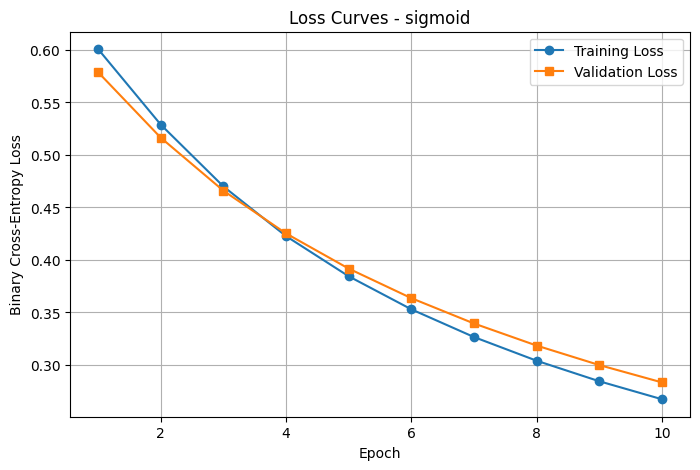

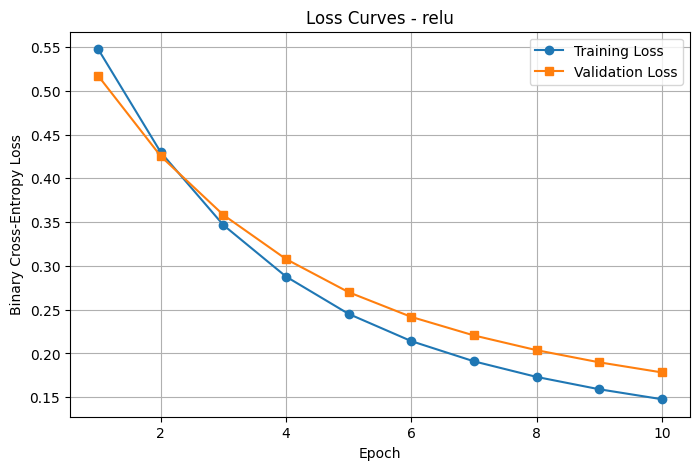

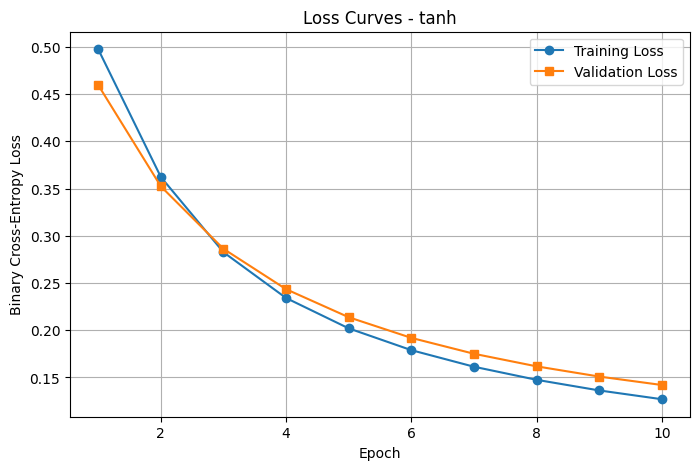

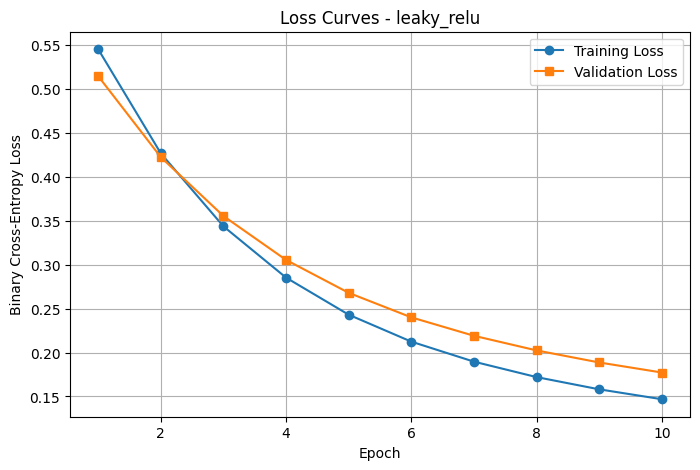

In [ ]:
# Import the plotting library
import matplotlib.pyplot as plt

# Define the 4 activation functions
activations = ["sigmoid", "relu", "tanh", "leaky_relu"]

# Define the epoch numbers: from 1 to 10
epochs_range = range(1, 11)

# Create one graph for each activation function
for activation_name in activations:

    # Create a new figure
    plt.figure(figsize=(8, 5))

    # Plot the training loss
    plt.plot(
        epochs_range,
        histories[activation_name]["loss"],
        marker="o",
        label="Training Loss"
    )

    # Plot the validation loss
    plt.plot(
        epochs_range,
        histories[activation_name]["val_loss"],
        marker="s",
        label="Validation Loss"
    )

    # Add the graph title and axis labels
    plt.title(f"Loss Curves - {activation_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")

    # Display the legend, grid, and graph
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:

import numpy as np

# True labels
y_true = np.array([1, 0, 1, 0, 1])

# Predicted probabilities
y_pred = np.array([0.9, 0.2, 0.8, 0.7, 0.6])

# Binary Cross-Entropy for each observation
epsilon = 1e-7
y_pred_safe = np.clip(y_pred, epsilon, 1 - epsilon)

losses = -(
    y_true * np.log(y_pred_safe)
    + (1 - y_true) * np.log(1 - y_pred_safe)
)

# Average loss across the 5 observations
cost = np.mean(losses)

print("Loss for each observation:")
for i, loss in enumerate(losses, start=1):
    print(f"Observation {i}: {loss:.4f}")

print(f"\nAverage Cost: {cost:.4f}")


Loss for each observation:
Observation 1: 0.1054
Observation 2: 0.2231
Observation 3: 0.2231
Observation 4: 1.2040
Observation 5: 0.5108

Average Cost: 0.4533


In [ ]:

# Store the trained models
models = {}
histories = {}

activations = ["sigmoid", "relu", "tanh", "leaky_relu"]

for activation_name in activations:
    print(f"\nTraining model with {activation_name} activation")

    model = build_model(activation_name)

    history = model.fit(
        X_train_final,
        y_train_final,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=0
    )

    models[activation_name] = model
    histories[activation_name] = history.history

print("\nAll models trained and saved successfully!")



Training model with sigmoid activation

Training model with relu activation

Training model with tanh activation

Training model with leaky_relu activation

All models trained and saved successfully!


In [ ]:

from sklearn.metrics import accuracy_score, log_loss
import pandas as pd
import numpy as np

results = []

for activation_name, model in models.items():

    # Evaluate the model on the test dataset
    y_pred_prob = model.predict(X_test, verbose=0).ravel()

    # Convert probabilities into binary predictions
    y_pred = (y_pred_prob >= 0.5).astype(int)

    # Calculate test accuracy and binary cross-entropy
    accuracy = accuracy_score(y_test, y_pred)
    test_cost = log_loss(y_test, y_pred_prob, labels=[0, 1])

    # Get final training and validation losses
    final_train_loss = histories[activation_name]["loss"][-1]
    final_val_loss = histories[activation_name]["val_loss"][-1]

    results.append({
        "Activation": activation_name,
        "Training Loss": final_train_loss,
        "Validation Loss": final_val_loss,
        "Test Cost": test_cost,
        "Test Accuracy (%)": accuracy * 100
    })

results_df = pd.DataFrame(results)

print("Comparison of the four activation functions:")
display(results_df.round(4))


Comparison of the four activation functions:


,Activation,Training Loss,Validation Loss,Test Cost,Test Accuracy (%)
0,sigmoid,0.2674,0.2834,0.2822,92.9825
1,relu,0.1476,0.1783,0.1963,92.9825
2,tanh,0.1270,0.1421,0.1739,94.7368
3,leaky_relu,0.1469,0.1773,0.1956,92.9825


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


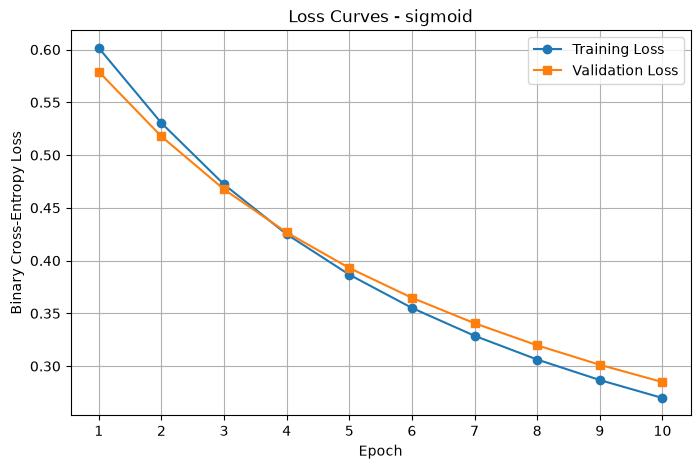

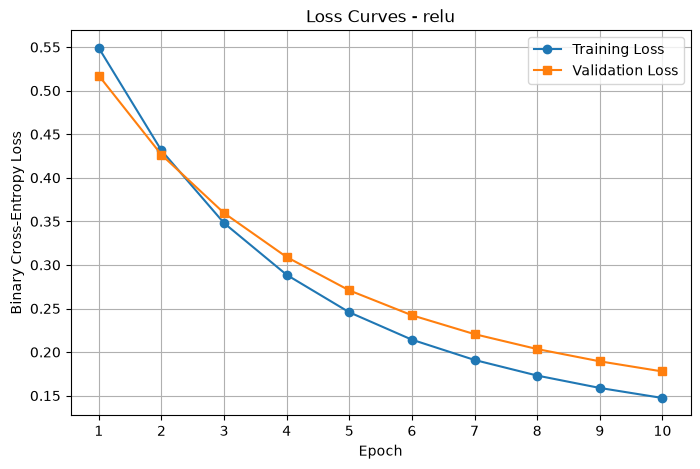

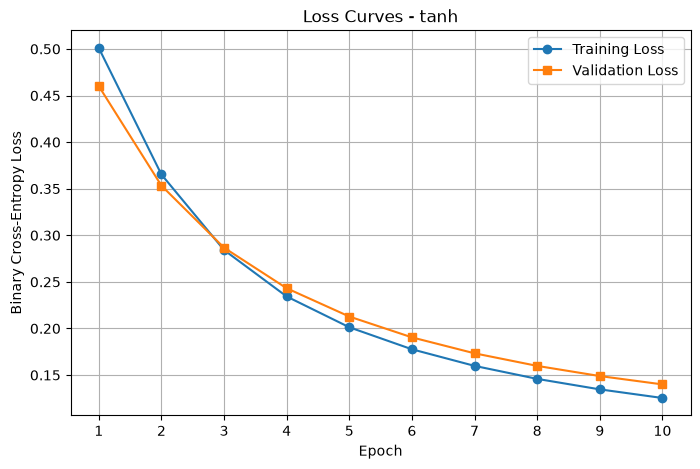

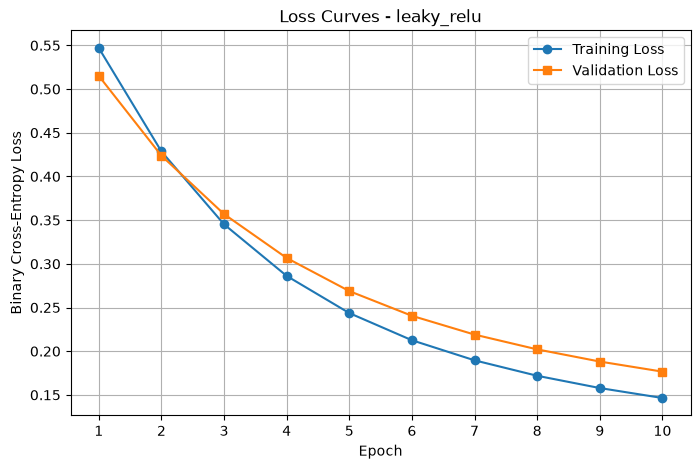

In [ ]:

import matplotlib.pyplot as plt

activations = ["sigmoid", "relu", "tanh", "leaky_relu"]
epochs_range = range(1, 11)

for activation_name in activations:
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        histories[activation_name]["loss"],
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        epochs_range,
        histories[activation_name]["val_loss"],
        marker="s",
        label="Validation Loss"
    )

    plt.title(f"Loss Curves - {activation_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")
    plt.xticks(epochs_range)
    plt.legend()
    plt.grid(True)
    plt.show()
